In [ ]:
import pandas as pd
import numpy as np
import re
import gradio as gr
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix
from lightgbm import LGBMClassifier

In [15]:
df = pd.read_csv('WELFake_Dataset.csv')

df = df.dropna(subset=['text'])
df = df.drop_duplicates(subset=['text'])

def clean_text(text):
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', '', text)
    return text

df['text'] = df['text'].apply(clean_text)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['label'], test_size=0.2, random_state=42)

--- BASE MODEL AUDIT (5-Fold CV on Training Data) ---

Evaluating Naive_Bayes...

Classification Report for Naive_Bayes:
              precision    recall  f1-score   support

           0       0.88      0.85      0.87     27698
           1       0.83      0.86      0.84     22476

    accuracy                           0.86     50174
   macro avg       0.85      0.86      0.86     50174
weighted avg       0.86      0.86      0.86     50174



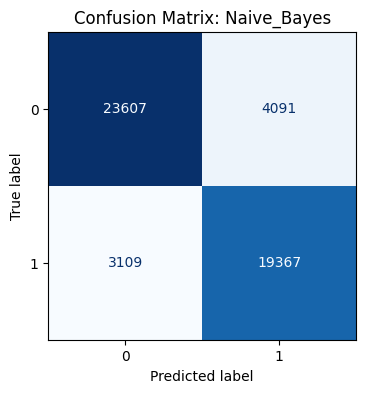

------------------------------------------------------------

Evaluating Logistic_Regression...

Classification Report for Logistic_Regression:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95     27698
           1       0.93      0.93      0.93     22476

    accuracy                           0.94     50174
   macro avg       0.94      0.94      0.94     50174
weighted avg       0.94      0.94      0.94     50174



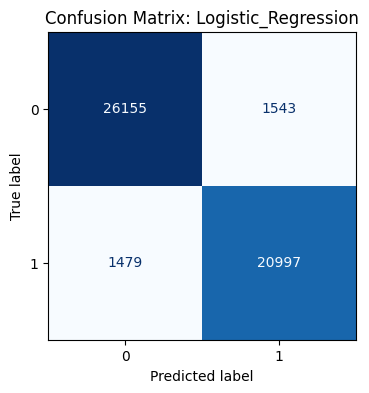

------------------------------------------------------------

Evaluating Calibrated_SVC...

Classification Report for Calibrated_SVC:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95     27698
           1       0.94      0.94      0.94     22476

    accuracy                           0.95     50174
   macro avg       0.95      0.95      0.95     50174
weighted avg       0.95      0.95      0.95     50174



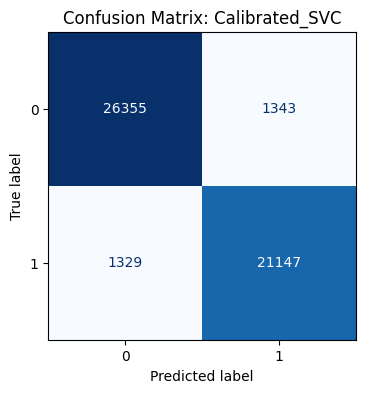

------------------------------------------------------------

Evaluating Decision_Tree...

Classification Report for Decision_Tree:
              precision    recall  f1-score   support

           0       0.91      0.90      0.90     27698
           1       0.88      0.88      0.88     22476

    accuracy                           0.89     50174
   macro avg       0.89      0.89      0.89     50174
weighted avg       0.89      0.89      0.89     50174



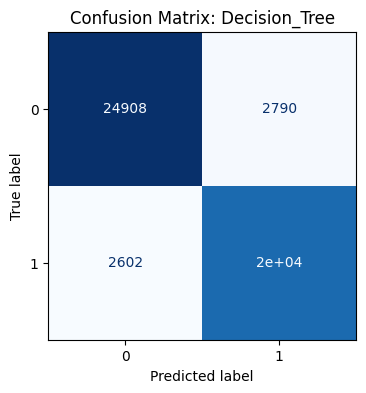

------------------------------------------------------------

Evaluating Random_Forest...

Classification Report for Random_Forest:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93     27698
           1       0.92      0.91      0.92     22476

    accuracy                           0.93     50174
   macro avg       0.93      0.92      0.93     50174
weighted avg       0.93      0.93      0.93     50174



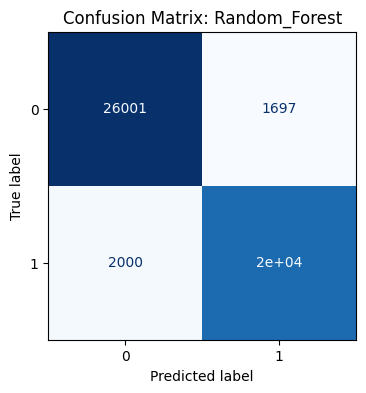

------------------------------------------------------------

Evaluating LightGBM...

Classification Report for LightGBM:
              precision    recall  f1-score   support

           0       0.96      0.95      0.96     27698
           1       0.94      0.95      0.95     22476

    accuracy                           0.95     50174
   macro avg       0.95      0.95      0.95     50174
weighted avg       0.95      0.95      0.95     50174



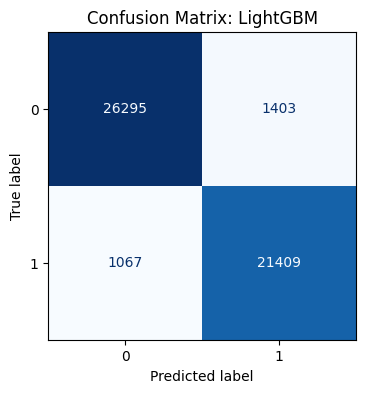

------------------------------------------------------------



In [ ]:

tfidf = TfidfVectorizer(stop_words='english', lowercase=True, ngram_range=(1, 2), max_features=10000)

# the base models, random state 42 for reducing tweaking
models = {
    'Naive_Bayes': MultinomialNB(),
    'Logistic_Regression': LogisticRegression(solver='saga', max_iter=500, random_state=42),
    'Calibrated_SVC': CalibratedClassifierCV(LinearSVC(random_state=42)),
    'Decision_Tree': DecisionTreeClassifier(max_depth=50, random_state=42),
    'Random_Forest': RandomForestClassifier(max_depth=50, n_estimators=100, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(random_state=42, n_jobs=-1)
}

print("5-Fold CV on Training Data\n")

for name, model in models.items():
    print(f"Evaluating {name}...")
    pipe = Pipeline([('tfidf', tfidf), ('clf', model)])
    cv_preds = cross_val_predict(pipe, X_train, y_train, cv=5, n_jobs=-1)
    
    print(f"\nClassification Report for {name}:")
    print(classification_report(y_train, cv_preds))
    
    # Plotting the confusion matrix. 0 is real and 1 is fake
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_train, 
        cv_preds, 
        ax=ax, 
        cmap='Blues', 
        colorbar=False
    )
    ax.set_title(f'Confusion Matrix: {name}')
    plt.show()
    
    print("-" * 60 + "\n")

In [24]:
def evaluate_ensemble(model_names, models, tfidf, X_train, y_train):
    selected = [(name, models[name]) for name in model_names]
    
    ensemble = VotingClassifier(
        estimators=selected,
        voting='soft',
        n_jobs=-1
    )
    
    pipeline = Pipeline([
        ('tfidf', tfidf),
        ('ensemble', ensemble)
    ])
    
    preds = cross_val_predict(
        pipeline,
        X_train,
        y_train,
        cv=5,
        n_jobs=-1
    )
    
    print(f"\nEnsemble: {model_names}")
    print(classification_report(y_train, preds))
    
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_train, preds, ax=ax, cmap='Purples'
    )
    plt.show()


Ensemble: ['Logistic_Regression', 'Calibrated_SVC', 'LightGBM']
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     27698
           1       0.95      0.95      0.95     22476

    accuracy                           0.95     50174
   macro avg       0.95      0.95      0.95     50174
weighted avg       0.95      0.95      0.95     50174



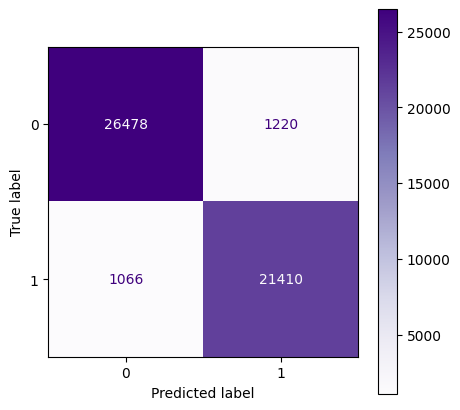


Ensemble: ['Naive_Bayes', 'Logistic_Regression', 'Calibrated_SVC', 'LightGBM']
              precision    recall  f1-score   support

           0       0.96      0.95      0.95     27698
           1       0.94      0.95      0.94     22476

    accuracy                           0.95     50174
   macro avg       0.95      0.95      0.95     50174
weighted avg       0.95      0.95      0.95     50174



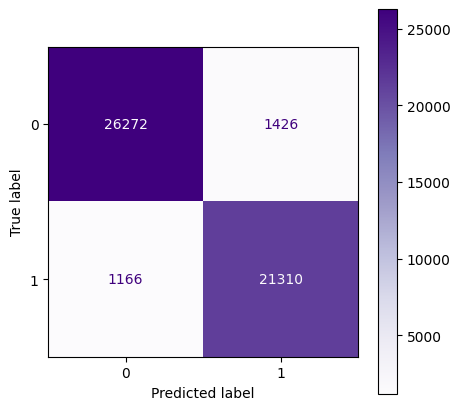

In [25]:

evaluate_ensemble(
    ['Logistic_Regression', 'Calibrated_SVC', 'LightGBM'],
    models, tfidf, X_train, y_train
)

evaluate_ensemble(
    ['Naive_Bayes', 'Logistic_Regression', 'Calibrated_SVC', 'LightGBM'],
    models, tfidf, X_train, y_train
)


Evaluation of final test

              precision    recall  f1-score   support

           0       0.96      0.96      0.96      6922
           1       0.95      0.95      0.95      5622

    accuracy                           0.96     12544
   macro avg       0.95      0.96      0.95     12544
weighted avg       0.96      0.96      0.96     12544



d:\University\fakenewsdetection\WELFake\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


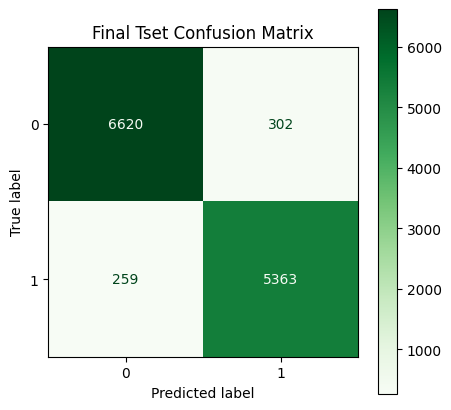

In [ ]:
# Define final ensemble (BEST MODEL) (For real this time lmao)
final_ensemble = VotingClassifier(
    estimators=[
        ('lr', models['Logistic_Regression']),
        ('svc', models['Calibrated_SVC']),
        ('lgbm', models['LightGBM'])
    ],
    voting='soft',
    n_jobs=-1
)

# Create one last pipeline before its all done
final_pipeline = Pipeline([
    ('tfidf', tfidf),
    ('ensemble', final_ensemble)
])

# Train on the full completer traingin data
final_pipeline.fit(X_train, y_train)

# Predict on test data
test_preds = final_pipeline.predict(X_test)

print("\nEvaluation of final test\n")
print(classification_report(y_test, test_preds))


fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_preds,
    ax=ax,
    cmap='Greens'
)
ax.set_title('Final Tset Confusion Matrix')
plt.show()

In [ ]:

def predict_news(text):
    probs = final_pipeline.predict_proba([text])[0]
    #In this dataset the real news is 0 and the fake news is 1. Pretty confusing at first    

    return {"Real News": float(probs[0]), "Fake News": float(probs[1])}

interface = gr.Interface(
    fn=predict_news,
    inputs=gr.Textbox(lines=10, placeholder="Paste a news article here to test the ensemble..."),
    outputs=gr.Label(num_top_classes=2),
    title="200143671 Fake News Detector",
    description="Made with a Soft-Voting Ensemble (Logistic Regression, Calibrated SVC, LightGBM). Percentages are not the chance of article being real or fake, but a display the average confidence scores of the models"
)

interface.launch()

* Running on local URL:  http://127.0.0.1:7869
* To create a public link, set `share=True` in `launch()`.


d:\University\fakenewsdetection\WELFake\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
d:\University\fakenewsdetection\WELFake\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
d:\University\fakenewsdetection\WELFake\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [31]:
import joblib

# Saving the entire process real quck
joblib.dump(final_pipeline, 'fyp_welfake_ensemble_model.pkl')


['fyp_welfake_ensemble_model.pkl']